# 01. MIT-BIH Arrhythmia Database Exploration

This notebook demonstrates loading, inspecting, and visualizing ECG records from the **MIT-BIH Arrhythmia Database** (PhysioNet `mitdb`).

### Objectives:
1. Load standard MIT-BIH records using WFDB.
2. Inspect sampling rate ($f_s = 360$ Hz), channel assignments (MLII, V5), and signal metadata.
3. Analyze expert beat annotations (Normal 'N', Ventricular 'V', Atrial 'A', etc.).
4. Visualize multi-second ECG waveforms with annotation markers.

In [1]:
%matplotlib inline
import sys
from pathlib import Path

# Ensure project root is in sys.path
project_root = Path('..').resolve()
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

import numpy as np
import matplotlib.pyplot as plt
from collections import Counter
from src.data_loader import load_record, print_record_summary
from src import config

## 1. Load Record 100
We load MIT-BIH record 100 into our structured `ECGRecord` dataclass.

In [2]:
ecg = load_record('100')
print_record_summary(ecg)

  ECG Record: 100
  Sampling frequency : 360 Hz
  Nyquist frequency  : 180 Hz
  Number of samples  : 650,000
  Duration           : 1,805.6 s  (30.1 min)
  Number of channels : 2
  Channel names      : ['MLII', 'V5']
  Units              : ['mV', 'mV']
  Signal shape       : (650000,)
  Signal range       : [-2.7150, 1.4350]
------------------------------------------------------------
  Total annotations  : 2,274
  Beat annotations   : 2,273
  Non-beat annotations: 1
  Annotation types   :
    'N' (beat): 2239
    'A' (beat): 33
    '+' (non-beat): 1
    'V' (beat): 1


## 2. Signal Properties and Lead Metadata

In [3]:
print(f'Sampling frequency : {ecg.sampling_frequency} Hz')
print(f'Total samples      : {ecg.num_samples:,}')
print(f'Total duration     : {ecg.duration_sec:.1f} s ({ecg.duration_sec / 60:.1f} min)')
print(f'Channels           : {ecg.channel_names}')
print(f'Signal amplitude   : min={ecg.signal.min():.3f} mV, max={ecg.signal.max():.3f} mV')
print(f'Signal mean        : {ecg.signal.mean():.4f} mV, std={ecg.signal.std():.4f} mV')

Sampling frequency : 360.0 Hz
Total samples      : 650,000
Total duration     : 1805.6 s (30.1 min)
Channels           : ['MLII', 'V5']
Signal amplitude   : min=-2.715 mV, max=1.435 mV
Signal mean        : -0.3063 mV, std=0.1932 mV


## 3. Beat vs Non-Beat Annotations
MIT-BIH annotations include both heartbeat classifications and auxiliary rhythm/signal comments.

In [4]:
sym_counts = Counter(ecg.annotation_symbols)
print(f'Total annotations: {len(ecg.annotation_symbols):,}')
print(f'Beat annotations : {ecg.num_beats:,}')
print('\nSymbol breakdown:')
for sym, count in sym_counts.most_common():
    is_beat = sym in config.BEAT_ANNOTATION_SYMBOLS
    kind = 'beat' if is_beat else 'non-beat marker'
    print(f'  [{sym}] : {count:>5} occurrences ({kind})')

Total annotations: 2,274
Beat annotations : 2,273

Symbol breakdown:
  [N] :  2239 occurrences (beat)
  [A] :    33 occurrences (beat)
  [+] :     1 occurrences (non-beat marker)
  [V] :     1 occurrences (beat)


## 4. Visualizing a 10-Second Window of Raw ECG
Observe the characteristic P-wave, QRS complex, and T-wave alongside baseline wander.

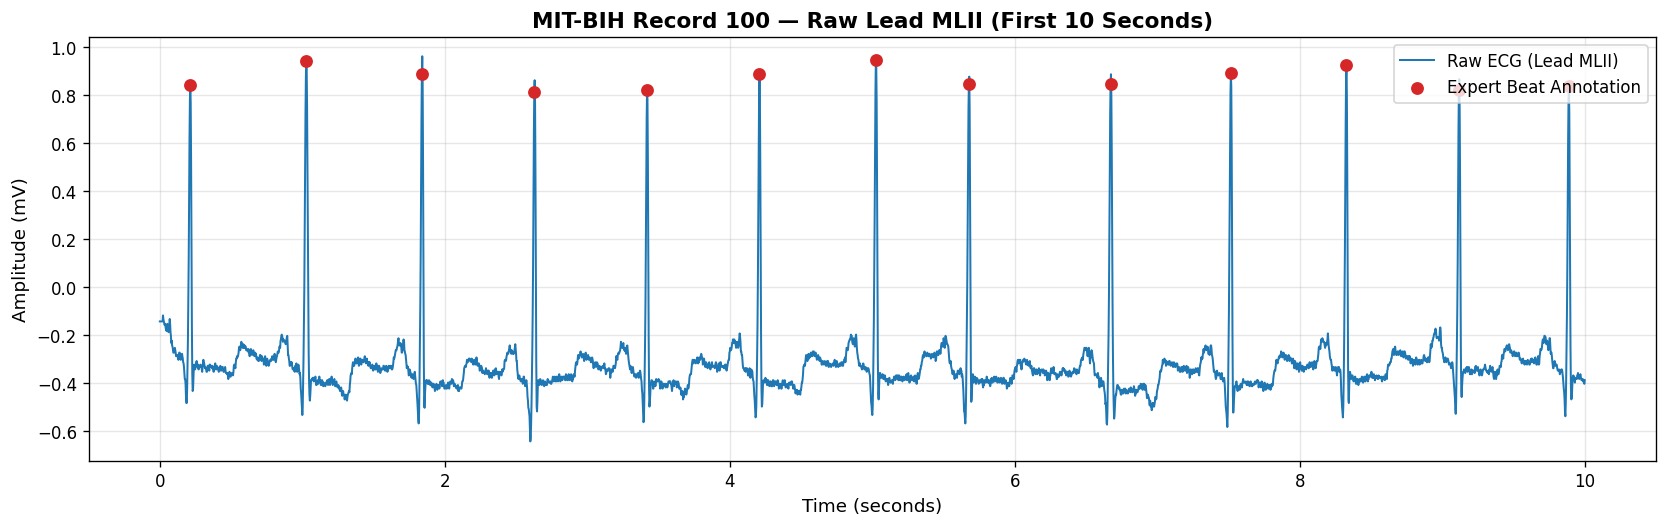

In [5]:
duration = 10.0
mask = ecg.time <= duration
t_win = ecg.time[mask]
sig_win = ecg.signal[mask]

# Reference beats within window
beat_mask = ecg.beat_times <= duration
b_times = ecg.beat_times[beat_mask]
b_samples = ecg.beat_samples[beat_mask]
b_amps = ecg.signal[b_samples]

plt.figure(figsize=(14, 4.5), dpi=120)
plt.plot(t_win, sig_win, color='#1f77b4', lw=1.2, label='Raw ECG (Lead MLII)')
plt.scatter(b_times, b_amps, color='#d62728', s=45, zorder=5, label='Expert Beat Annotation')
plt.title('MIT-BIH Record 100 — Raw Lead MLII (First 10 Seconds)', fontsize=13, fontweight='bold')
plt.xlabel('Time (seconds)', fontsize=11)
plt.ylabel('Amplitude (mV)', fontsize=11)
plt.grid(True, alpha=0.3)
plt.legend(loc='upper right')
plt.tight_layout()
plt.show()